### Top Rows

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# -------------------------------------------------
# 1. Replace "x" with 1800 in ORIGINAL df (in place)
# -------------------------------------------------

file_path = "results-filtered-dataset.txt"

# Read the first sheet
# df = pd.read_excel(file_path)
df = pd.read_csv(file_path, sep=r"\s+")

noAltRB = ["UMKP-S", "UMKP-R", "UMKP-P"]
AltRB = ["UMKP+-S", "UMKP+-R", "UMKP+-P"]

all_algos = noAltRB + AltRB

df[all_algos] = df[all_algos].replace("x", 1800).apply(pd.to_numeric)


In [7]:
df["noAltRB_min"] = df[noAltRB].min(axis=1)
df["AltRB_min"] = df[AltRB].min(axis=1)

df["ratio"] = np.maximum(df["noAltRB_min"], df["AltRB_min"]) / np.minimum(df["noAltRB_min"], df["AltRB_min"])

filtered_rows = df[
    (df["noAltRB_min"] > 1) &
    (df["AltRB_min"] > 1) &
    (df["ratio"] >= 10)
].sort_values(by="ratio", ascending=False).copy()

# Split into two tables
noAltRB_wins_table = filtered_rows[filtered_rows["noAltRB_min"] < filtered_rows["AltRB_min"]]
AltRB_wins_table  = filtered_rows[filtered_rows["AltRB_min"] < filtered_rows["noAltRB_min"]]

total = len(filtered_rows)

display(Markdown(f"""
## Experiment Summary
### Filtered rows: **{total}**
- noAltRB faster: **{len(noAltRB_wins_table)}**
- AltRB faster: **{len(AltRB_wins_table)}**
"""))

display(Markdown("## noAltRB Wins"))
print(noAltRB_wins_table[["dataset", "k", "noAltRB_min", "AltRB_min", "ratio"]])

display(Markdown("## AltRB Wins"))
print(AltRB_wins_table[["dataset", "k", "noAltRB_min", "AltRB_min", "ratio"]])


## Experiment Summary
### Filtered rows: **158**
- noAltRB faster: **31**
- AltRB faster: **127**


## noAltRB Wins

                dataset   k  noAltRB_min  AltRB_min       ratio
3109             Sieber   5     3.515022  1800.0000  512.087833
3930   TSOPF_FS_b300_c1   8    12.660776  1800.0000  142.171380
3931   TSOPF_FS_b300_c1   9    16.581972  1800.0000  108.551625
4286  wikipedia_link_sr  20    18.242677  1800.0000   98.669729
4282  wikipedia_link_sr   8    18.431310  1800.0000   97.659906
4279  wikipedia_link_sr   5    19.694109  1800.0000   91.397890
4285  wikipedia_link_sr  15    20.151321  1800.0000   89.324169
4278  wikipedia_link_sr   4    20.155062  1800.0000   89.307589
4276  wikipedia_link_sr   2    20.486646  1800.0000   87.862113
4277  wikipedia_link_sr   3    21.467536  1800.0000   83.847536
4280  wikipedia_link_sr   6    21.488014  1800.0000   83.767630
4283  wikipedia_link_sr   9    21.764150  1800.0000   82.704815
1850             karted  15    22.569116  1800.0000   79.755007
693          Chebyshev4  20    36.825637  1800.0000   48.878992
1846             karted   7    50.353590

## AltRB Wins

                       dataset   k  noAltRB_min  AltRB_min        ratio
2628                  pkustk09  20  1800.000000     1.1179  1610.161911
3996          TSOPF_RS_b162_c1  20  1800.000000     1.1951  1506.150113
3999          TSOPF_RS_b162_c3  20  1800.000000     1.2744  1412.429379
3998          TSOPF_RS_b162_c3  10  1800.000000     1.3113  1372.683596
3954          TSOPF_FS_b300_c3  10  1800.000000     1.5496  1161.590088
...                        ...  ..          ...        ...          ...
1087               edit-jawiki   5   609.506109    58.2978    10.455045
2563                   pics_ui  10   217.429089    21.2645    10.224980
1119               edit-ptwiki  15   778.106643    76.3851    10.186629
562   bookcrossing_full-rating  20  1800.000000   178.0156    10.111473
3929          TSOPF_FS_b300_c1   5  1800.000000   178.5018    10.083932

[127 rows x 5 columns]


### Winning Algorithm Counts

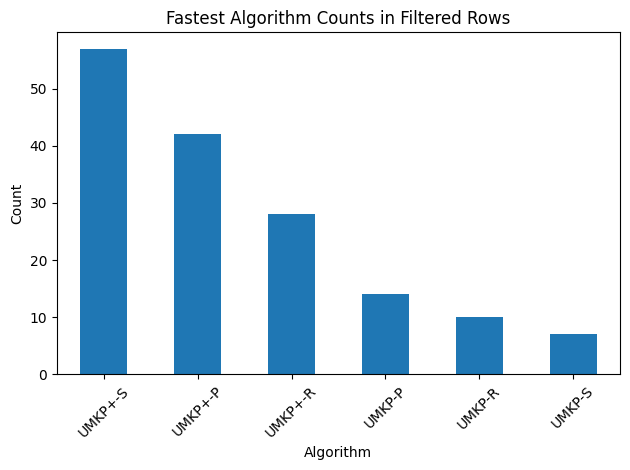

In [8]:
# algorithm that is fastest per row
filtered_rows["fastest_algo"] = filtered_rows[all_algos].idxmin(axis=1)

# count occurrences
algo_counts = filtered_rows["fastest_algo"].value_counts()

algo_counts.plot(kind="bar")

plt.xlabel("Algorithm")
plt.ylabel("Count")
plt.title("Fastest Algorithm Counts in Filtered Rows")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Varying Ratio Threshold

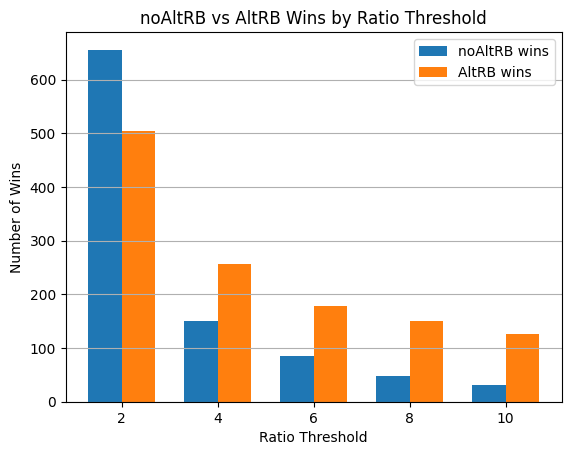

In [9]:
ratio_thresholds = [2, 4, 6, 8, 10]

noAltRB_wins_list = []
AltRB_wins_list = []

df["ratio"] = np.maximum(df["noAltRB_min"], df["AltRB_min"]) / np.minimum(df["noAltRB_min"], df["AltRB_min"])

for r in ratio_thresholds:
    filtered_rows = df[
        (df["noAltRB_min"] > 1) &
        (df["AltRB_min"] > 1) &
        (df["ratio"] >= r)
    ]

    total = len(filtered_rows)
    noAltRB_wins = (filtered_rows["noAltRB_min"] < filtered_rows["AltRB_min"]).sum()
    AltRB_wins = total - noAltRB_wins

    noAltRB_wins_list.append(noAltRB_wins)
    AltRB_wins_list.append(AltRB_wins)

# Bar chart
x = np.arange(len(ratio_thresholds))
width = 0.35

plt.figure()
plt.bar(x - width/2, noAltRB_wins_list, width, label="noAltRB wins")
plt.bar(x + width/2, AltRB_wins_list, width, label="AltRB wins")

plt.xticks(x, ratio_thresholds)
plt.xlabel("Ratio Threshold")
plt.ylabel("Number of Wins")
plt.title("noAltRB vs AltRB Wins by Ratio Threshold")
plt.legend()
plt.grid(axis="y")

plt.show()